## Ćwiczenie 13: Analiza rzeczywistych danych medycznych 3D — MPR, MIP / MinIP oraz Wolumetria

### Wprowadzenie i cel ćwiczenia
W tym ćwiczeniu pracujesz na **prawdziwym badaniu rezonansu magnetycznego mózgowia 3D (`skimage.data.brain()`)** wczytanym bezpośrednio z biblioteki `scikit-image` (10 przekrojów osiowych `10 × 256 × 256` wokseli o anizotropowej siatce przestrzennej `Spacing = (0.94, 0.94, 5.00) mm` — typowej dla klinicznego protokołu MRI głowy z warstwami co 5 mm).

Twoim zadaniem jest uzupełnienie trzech funkcji w Kroku 2 (oznaczonych `# TODO`):
1. **`resample_to_isotropic()`** — przekształcenie anizotropowego badania MRI 3D do siatki izotropowej $1.0 \times 1.0 \times 1.0\;\text{mm}$,
2. **`extract_mpr_and_projections()`** — wyznaczenie trzech ortogonalnych przekrojów **MPR** (*Axial*, *Coronal*, *Sagittal*) w zadanym punkcie anatomicznym oraz projekcji **Coronal MIP** (ukazującej hiperintensywne struktury naczyniowe i kości/tkankę tłuszczową) i **Coronal MinIP** (ukazującej układ komorowy wypełniony płynem mózgowo-rdzeniowym),
3. **`quantify_structure_3d()`** — segmentacja progowa i morfologiczna wybranej struktury anatomicznej wewnątrz zadanego obszaru zainteresowania (ROI 3D) oraz obliczenie jej objętości w $\text{cm}^3$, średniej intensywności sygnału i wymiarów w milimetrach.

In [4]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK scikit-image pooch scipy pandas

import SimpleITK as sitk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data
from scipy.ndimage import binary_fill_holes, binary_opening

print(f"Środowisko 3D gotowe (SimpleITK {sitk.__version__})")

Środowisko 3D gotowe (SimpleITK 2.5.7)


---
### Krok 1: Pobranie rzeczywistego wolumenu MRI 3D z biblioteki i przypisanie metadanych geometrycznych

Funkcja `skimage.data.brain()` pobiera prawdziwy stos **10 przekrojów osiowych MRI mózgu** w postaci tablicy NumPy o kształcie `(10, 256, 256)`. Ponieważ surowa tablica NumPy nie przechowuje informacji o wymiarach fizycznych woksela, w poniższej komórce opakowujemy ją w obiekt `sitk.Image` z rzeczywistymi metadanymi geometrycznymi klinicznego badania MRI głowy:
* `Spacing = (0.94, 0.94, 5.00) mm` (rozdzielczość w płaszczyźnie przekroju $0.94\;\text{mm}$, grubość/odstęp warstw $5.00\;\text{mm}$ — współczynnik anizotropii $> 5.3\times$),
* `Origin = (-120.0, -120.0, -25.0) mm` w układzie współrzędnych pacjenta LPS.

Wczytano rzeczywisty wolumen MRI mózgu: (256, 256, 10) wokseli (X, Y, Z)
Rozmiar woksela Spacing (mm)          : (0.94, 0.94, 5.0)
Punkt początkowy Origin (mm)          : (-120.0, -120.0, -25.0)
Zakres intensywności sygnału          : [0, 51076]


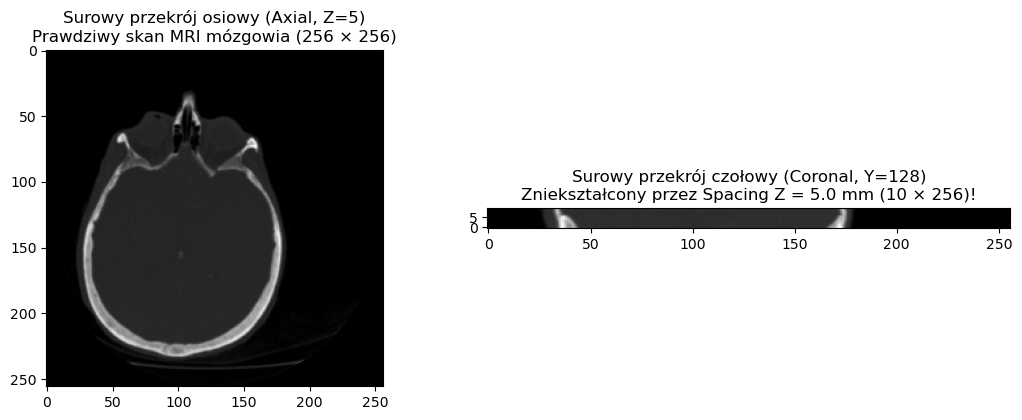

In [8]:
# 1. Pobranie prawdziwego wolumenu MRI mózgu 3D z biblioteki scikit-image
brain_arr = data.brain().astype(np.float32)  # kształt (Z=10, Y=256, X=256)

# 2. Utworzenie obiektu 3D SimpleITK z rzeczywistym Spacing i Origin (w mm)
vol_3d = sitk.GetImageFromArray(brain_arr)
orig_spacing = (0.94, 0.94, 5.00)     # (dx, dy, dz) w mm
orig_origin = (-120.0, -120.0, -25.0) # (ox, oy, oz) w mm
vol_3d.SetSpacing(orig_spacing)
vol_3d.SetOrigin(orig_origin)

print(f"Wczytano rzeczywisty wolumen MRI mózgu: {vol_3d.GetSize()} wokseli (X, Y, Z)")
print(f"Rozmiar woksela Spacing (mm)          : {vol_3d.GetSpacing()}")
print(f"Punkt początkowy Origin (mm)          : {vol_3d.GetOrigin()}")
print(f"Zakres intensywności sygnału          : [{brain_arr.min():.0f}, {brain_arr.max():.0f}]")

# Podgląd surowego przekroju osiowego (Z=5) oraz spłaszczonego przekroju czołowego (Y=128)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].imshow(brain_arr[5, :, :], cmap="gray")
ax[0].set_title("Surowy przekrój osiowy (Axial, Z=5)\nPrawdziwy skan MRI mózgowia (256 × 256)")
ax[1].imshow(brain_arr[:, 128, :], cmap="gray", origin="lower")
ax[1].set_title("Surowy przekrój czołowy (Coronal, Y=128)\nZniekształcony przez Spacing Z = 5.0 mm (10 × 256)!")
plt.tight_layout()
plt.show()

---
## Krok 2: Implementacja funkcji analizy 3D, MPR / MIP / MinIP oraz wolumetrii (`# TODO`)

Uzupełnij trzy poniższe funkcje:

### 1. `resample_to_isotropic(image_3d, new_spacing=(1.0, 1.0, 1.0))` (`# TODO 1`)
* Oblicz nowy rozmiar macierzy `new_size` dla każdej z 3 osi $i \in \{0, 1, 2\}$:  
  $$\text{new\_size}[i] = \text{round}\left(\text{orig\_size}[i] \cdot \frac{\text{orig\_spacing}[i]}{\text{new\_spacing}[i]}\right)$$
* Skonfiguruj filtr `sitk.ResampleImageFilter()` z interpolacją trójliniową (`sitk.sitkLinear`), wartością tła `0.0`, zachowując oryginalne `Origin` oraz `Direction`.

### 2. `extract_mpr_and_projections(vol_iso, target_mm=(0.0, 5.0, 0.0), slab_thickness_mm=24)` (`# TODO 2`)
* Przelicz fizyczne współrzędne punktu referencyjnego `target_mm` na indeksy woksela `(ix, iy, iz)` za pomocą `vol_iso.TransformPhysicalPointToIndex(target_mm)`.
* Pobierz tablicę NumPy `arr = sitk.GetArrayFromImage(vol_iso)` o kształcie `(Z, Y, X)` i wyodrębnij trzy przekroje MPR: `axial = arr[iz, :, :]`, `coronal = arr[:, iy, :]`, `sagittal = arr[:, :, ix]`.
* Wytnij grubą warstwę (*slab*) o grubości `slab_thickness_mm` wyśrodkowaną wokół indeksu `iy` (pamiętaj o zabezpieczeniu granic `max(0, ...)` i `min(arr.shape[1], ...)`) i oblicz:
  * `coronal_mip = np.max(slab, axis=1)` — projekcję maksymalnej intensywności (MIP),
  * `coronal_minip = np.min(slab, axis=1)` — projekcję minimalnej intensywności (MinIP).

### 3. `quantify_structure_3d(vol_iso, target_mm=(0.0, 5.0, 0.0), half_box_mm=(32, 42, 18), intensity_range=(80.0, 255.0))` (`# TODO 3`)
* Wytnij prostopadłościenny podwolumen `roi_sub` o półosiach `half_box_mm = (hx_mm, hy_mm, hz_mm)` wokół punktu `(ix, iy, iz)`.
* Wyznacz maskę progową `raw_mask = (roi_sub >= low) & (roi_sub <= high)`, a następnie wygładź ją morfologicznie za pomocą `binary_opening(raw_mask)` oraz wypełnij wewnętrzne drobne ubytki za pomocą `binary_fill_holes(...)`, tworząc finalną maskę `clean_mask`.
* Oblicz objętość pojedynczego woksela w $\text{cm}^3$ ($1\;\text{cm}^3 = 1000\;\text{mm}^3$) na podstawie `vol_iso.GetSpacing()` i wyznacz:
  * `volume_cm3` — objętość wysegmentowanej struktury w $\text{cm}^3$,
  * `mean_intensity` — średnią intensywność sygnału wewnątrz `clean_mask`,
  * `std_intensity` — odchylenie standardowe intensywności wewnątrz `clean_mask`,
  * `extent_x_mm`, `extent_y_mm`, `extent_z_mm` — wymiary fizyczne (rozpiętość w mm) wysegmentowanej struktury w osiach $X$, $Y$ i $Z$.

In [ ]:
# ---------------------------------------------------------
# MIEJSCE NA TWÓJ KOD (Ćwiczenie na rzeczywistym skanie 3D)
# ---------------------------------------------------------

def resample_to_isotropic(image_3d, new_spacing=(1.0, 1.0, 1.0)):
    """
    Przeskalowuje wolumen 3D SimpleITK do zadanej rozdzielczości izotropowej (w mm).
    """
    # TODO 1: Oblicz new_size, skonfiguruj sitk.ResampleImageFilter() (sitkLinear, default=0.0)
    # i zwróć przeskalowany wolumen SimpleITK.
    pass


def extract_mpr_and_projections(vol_iso, target_mm=(0.0, 5.0, 0.0), slab_thickness_mm=24):
    """
    Wyznacza indeksy woksela (ix, iy, iz) dla punktu target_mm, trzy przekroje MPR
    (axial, coronal, sagittal) oraz projekcje Coronal MIP i Coronal MinIP.
    """
    # TODO 2: Użyj TransformPhysicalPointToIndex(), wyodrębnij przekroje MPR z tablicy (Z, Y, X)
    # oraz oblicz coronal_mip (np.max) i coronal_minip (np.min) wzdłuż osi Y.
    pass


def quantify_structure_3d(vol_iso, target_mm=(0.0, 5.0, 0.0), half_box_mm=(32, 42, 18), intensity_range=(80.0, 255.0)):
    """
    Segmentuje strukturę w zadanym ROI 3D wokół target_mm na podstawie progu intensywności,
    oczyszcza maskę morfologicznie (binary_opening + binary_fill_holes) i oblicza metryki 3D.
    """
    # TODO 3: Wytnij podwolumen roi_sub, utwórz clean_mask = binary_fill_holes(binary_opening(raw_mask)),
    # a następnie oblicz statystyki objętościowe i zwróć (metrics, roi_sub, clean_mask).
    pass


# =========================================================
# WERYFIKACJA WYNIKÓW I WIZUALIZACJA MPR / MIP / MinIP / 3D
# =========================================================
vol_iso = resample_to_isotropic(vol_3d, new_spacing=(1.0, 1.0, 1.0))

if vol_iso is not None:
    target_pt = (0.0, 5.0, 0.0)
    proj_dict = extract_mpr_and_projections(vol_iso, target_mm=target_pt, slab_thickness_mm=24)
    metrics, roi_sub, clean_mask = quantify_structure_3d(
        vol_iso, target_mm=target_pt, half_box_mm=(32, 42, 18), intensity_range=(80.0, 255.0)
    )

    df_metrics = pd.DataFrame.from_dict(metrics, orient="index", columns=["Wartość"])
    display(df_metrics.round(2))

    ix, iy, iz = proj_dict["indices"]
    fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))

    # Wiersz 1: Trzy ortogonalne płaszczyzny MPR z celownikiem w punkcie referencyjnym
    ax[0, 0].imshow(proj_dict["axial"], cmap="gray")
    ax[0, 0].axvline(ix, color="cyan", linestyle="--", lw=1.1)
    ax[0, 0].axhline(iy, color="cyan", linestyle="--", lw=1.1)
    ax[0, 0].set_title(f"Axial MPR (Z = {target_pt[2]} mm)")

    ax[0, 1].imshow(proj_dict["coronal"], cmap="gray", origin="lower")
    ax[0, 1].axvline(ix, color="cyan", linestyle="--", lw=1.1)
    ax[0, 1].axhline(iz, color="cyan", linestyle="--", lw=1.1)
    ax[0, 1].set_title(f"Coronal MPR (Y = {target_pt[1]} mm)")

    ax[0, 2].imshow(proj_dict["sagittal"], cmap="gray", origin="lower")
    ax[0, 2].axvline(iy, color="cyan", linestyle="--", lw=1.1)
    ax[0, 2].axhline(iz, color="cyan", linestyle="--", lw=1.1)
    ax[0, 2].set_title(f"Sagittal MPR (X = {target_pt[0]} mm)")

    # Wiersz 2: Coronal MIP, Coronal MinIP oraz przekrój centralny segmentacji 3D w ROI
    ax[1, 0].imshow(proj_dict["coronal_mip"], cmap="gray", origin="lower")
    ax[1, 0].set_title("Coronal MIP (grubość 24 mm)\nMaksymalna intensywność wzdłuż osi Y")

    ax[1, 1].imshow(proj_dict["coronal_minip"], cmap="gray", origin="lower")
    ax[1, 1].set_title("Coronal MinIP (grubość 24 mm)\nMinimalna intensywność (struktury hipointensywne)")

    mid_z = roi_sub.shape[0] // 2
    ax[1, 2].imshow(roi_sub[mid_z, :, :], cmap="gray")
    ax[1, 2].contour(clean_mask[mid_z, :, :], colors="lime", linewidths=1.6)
    ax[1, 2].set_title(f"Segmentacja 3D w ROI (przekrój Z)\nObjętość = {metrics['Objętość wysegmentowanej struktury [cm3]']:.2f} cm³")

    plt.tight_layout()
    plt.show()
else:
    print("Uzupełnij funkcje TODO 1, TODO 2 oraz TODO 3 powyżej!")

---
## Krok 3: Pytania kontrolne i analiza wyników (do uzupełnienia)

Na podstawie wygenerowanych rekonstrukcji MPR, projekcji MIP/MinIP oraz tabeli pomiarów wolumetrycznych odpowiedz krótko na poniższe pytania:

1. **Porównaj surowy przekrój czołowy (`Coronal`) z Kroku 1 z przekrojem `Coronal MPR` po resamplingu izotropowym z Kroku 2. Co zmieniło się w geometrii obrazu i z czego to wynika?**  
   *Twoja odpowiedź:* ...

2. **Czym różni się obraz uzyskany w projekcji `Coronal MIP` od projekcji `Coronal MinIP` na tym samym skanie MRI mózgu i jakie struktury anatomiczne są lepiej widoczne w każdej z nich?**  
   *Twoja odpowiedź:* ...

3. **Jaki wpływ na wynik wolumetrii w funkcji `quantify_structure_3d()` miałoby pominięcie etapu `resample_to_isotropic()` i wykonanie pomiaru bezpośrednio na surowej tablicy `brain_arr` (`10 × 256 × 256`)?**  
   *Twoja odpowiedź:* ...